# PickleSimulator: pre-simulated data with the conjugate method

`PickleSimulator` serves data that was simulated elsewhere, read from a
directory of `.pkl` files, through the same interface as the benchmark
simulators (`prior`, `simulate`, `generate_training_data`,
`generate_observed_data`).

This notebook:
1. Writes an example data directory, using the SIR simulator as a stand-in
   for an external simulator.
2. Loads it with `PickleSimulator(data_dir)`.
3. Draws training data and contaminated observed data.
4. Trains the conjugate `EnergyBasedModel`.
5. Calibrates $\beta$ with GPC and computes the calibrated posterior.

All settings are the values in `configs/sir.yaml`, passed directly as
function arguments.

In [ ]:
from pathlib import Path
import pickle

import matplotlib.pyplot as plt
import torch

from nsm_bayes.inference.conjugate.calibrate_beta import calibrate_beta_gpc
from nsm_bayes.models.conjugate import EnergyBasedModel
from nsm_bayes.models.conjugate.conj_posterior import ConjugatePosterior
from nsm_bayes.simulators.benchmark_simulators.sir import SIRSimulator
from nsm_bayes.utils import set_seed

# Repository root, whether the notebook is run from examples/ or the root
REPO = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent

set_seed(123)

## 1. Writing the data directory

`PickleSimulator` expects these files in `data_dir`; each holds one array
(torch tensor, numpy array, list or DataFrame):

| file | shape | |
|---|---|---|
| `theta.pkl` | `(N, d_theta)` | parameters, required |
| `x_sim.pkl` | `(N, d_x)` | simulation at each row of `theta`, required |
| `x_obs.pkl` | `(M, d_x)` | observed data, required |
| `theta_true.pkl` | `(d_theta,)` | parameter `x_obs` was generated at, optional |
| `prior_mean.pkl`, `prior_cov.pkl` | `(d_theta,)`, `(d_theta, d_theta)` | Gaussian prior, optional for diagnostics only |

In practice these come from your own simulator. Here we create them with
the SIR simulator, exactly as the SIR experiment does: 50,000 prior draws
with their summary statistics, and 1,000 clean observations at the true
parameter. Parameters are in unconstrained space
$(\log \beta, \log \gamma, \mathrm{logit}\,\rho, \log I_0)$.
The prior mean and true parameter in `sir.yaml` are on the natural scale
$(\beta, \gamma, \rho, I_0)$, so both are mapped to that space.

In [3]:
#generating some dummy data files
#im using the sir defaults, but they could be anything. 
data_dir = REPO / "data" / "sir_pickle"
data_dir.mkdir(parents=True, exist_ok=True)

def to_unconstrained(values):
    """(beta, gamma, rho, I0) -> (log beta, log gamma, logit rho, log I0)."""
    v = torch.tensor(values, dtype=torch.float32)
    return torch.stack([v[0].log(), v[1].log(), torch.logit(v[2]), v[3].log()])

# The prior mean and true parameter are on the natural scale, so both are
# transformed; the prior standard deviations are already in unconstrained space.
sir = SIRSimulator(
    prior_mean=to_unconstrained([0.5, 0.2, 0.5, 20.0]),
    prior_cov=torch.diag(torch.tensor([0.5, 0.5, 1.0, 0.7]) ** 2),
)
theta_true = to_unconstrained([0.6, 0.15, 0.6, 20.0])

theta, y_sim = sir.generate_training_data(1000)

#generate misspecified observation data 
x_obs_mis,_ = sir.generate_contaminated_data(theta_true, n_obs=100, epsilon=0.05)

arrays = {
    "theta": theta,
    "x_sim": sir.summary(y_sim),
    "x_obs": sir.summary(x_obs_mis),
    "theta_true": theta_true,
    "prior_mean": sir.prior_mean,
    "prior_cov": sir.prior_cov,
}

#save them 
for name, arr in arrays.items():
    with open(data_dir / f"{name}.pkl", "wb") as fh:
        pickle.dump(arr, fh)
    print(f"{name}.pkl: {tuple(arr.shape)}")

theta.pkl: (1000, 4)
x_sim.pkl: (1000, 3)
x_obs.pkl: (100, 3)
theta_true.pkl: (4,)
prior_mean.pkl: (4,)
prior_cov.pkl: (4, 4)


## 3. Training and observed data

`generate_training_data(n)` draws `n` stored $(\theta_i, x_i)$ pairs
without replacement; with `n = 50000` that is all of them.

`generate_observed_data(theta, n_obs, epsilon)` draws `n_obs` rows of
`x_obs.pkl` and replaces a fraction $\epsilon$ of them with simulations
under random prior parameters (rows of `x_sim.pkl`), the same prior
contamination as the SIR experiment. `theta` must match `theta_true.pkl`,
because stored observations cannot be re-simulated at another parameter.

`simulate(theta)` returns the stored simulation for parameters that are
in `theta.pkl`.

In [4]:
from nsm_bayes.simulators.fromdata import load_pkl

#define the training data from the files
theta = load_pkl(str(data_dir)+"/theta.pkl")
x_sim = load_pkl(str(data_dir)+"/x_sim.pkl")

## 4. Training the conjugate model

`EnergyBasedModel` fits standardizers on the simulations and trains the
networks $T_\phi$ and $b_\phi$ by score matching, giving the surrogate
likelihood

\begin{equation*}
q_\phi(x \mid \theta) \propto \exp\{T_\phi(x)^\top \theta + b_\phi(x)\}.
\end{equation*}

In [5]:
d_x = x_sim.shape[1]
d_theta = theta.shape[1]

model = EnergyBasedModel(d_x=d_x, d_theta=d_theta, hidden_dim=16)

model.fit(x_sim=x_sim, theta_sim=theta)

history = model.train_history
plt.figure(figsize=(7, 3.5))
plt.plot(history["train_losses"], label="train")
plt.plot(history["val_losses"], label="validation")
plt.xlabel("epoch")
plt.ylabel("score-matching loss")
plt.legend()
plt.grid(True)
plt.show()

Starting training for q_phi...


/u/08/sohkanj1/unix/Documents/projects/nsm-bayes/myenv/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Epoch [1/1000] | Train Loss: 1.820107 | Val Loss: 1.582040
Epoch [10/1000] | Train Loss: 0.476958 | Val Loss: 0.394198
Epoch [20/1000] | Train Loss: -0.422367 | Val Loss: -0.462240
Epoch [30/1000] | Train Loss: -1.133460 | Val Loss: -1.102690
Epoch [40/1000] | Train Loss: -1.806549 | Val Loss: -1.783444
Epoch [50/1000] | Train Loss: -2.682271 | Val Loss: -2.586702
Epoch [60/1000] | Train Loss: -3.645140 | Val Loss: -3.532198
Epoch [70/1000] | Train Loss: -4.812609 | Val Loss: -4.636596
Epoch [80/1000] | Train Loss: -5.985292 | Val Loss: -5.885937
Epoch [90/1000] | Train Loss: -7.523363 | Val Loss: -7.261791
Epoch [100/1000] | Train Loss: -8.763364 | Val Loss: -8.751298
Epoch [110/1000] | Train Loss: -10.449415 | Val Loss: -10.330737
Epoch [120/1000] | Train Loss: -12.144673 | Val Loss: -11.983309
Epoch [130/1000] | Train Loss: -13.847464 | Val Loss: -13.703573
Epoch [140/1000] | Train Loss: -15.363153 | Val Loss: -15.453125
Epoch [150/1000] | Train Loss: -17.280843 | Val Loss: -17.2795

KeyboardInterrupt: 

## 5. Calibrating $\beta$

The score-matching loss is not a log-likelihood, so the generalised
posterior $\pi(\theta)\,\exp\{-\beta\, n\, L(\theta; x)\}$ needs a
temperature $\beta$. Too large a $\beta$ gives an overconfident posterior;
too small a $\beta$ returns the prior. `calibrate_beta_gpc` tunes $\beta$
by general posterior calibration (GPC), matching the bootstrap coverage
of the $1 - \alpha$ credible region to its nominal level.

`robust=True` in `ConjugatePosterior` switches to robust (IMQ-weighted)
estimates of the data statistics.

In [ ]:
from nsm_bayes.simulators.fromdata import gaussian_mle_from_data

In [ ]:
prior_mean = load_pkl(str(data_dir)+"/prior_mean.pkl")
prior_cov = load_pkl(str(data_dir)+"/prior_cov.pkl")

#or estimate from the data 
prior_mean, prior_cov = gaussian_mle_from_data(theta)

posterior = ConjugatePosterior(
    model,
    prior_mean,
    prior_cov,
    robust=False,
    weight_type="imq",
)

beta, gpc_history = calibrate_beta_gpc(
    x_obs_mis,
    posterior,
    initial_beta=0.01,
    target_coverage=0.95,
    num_iterations=20,
    num_bootstraps=100,
    beta_min=1e-4,
)
print(f"calibrated beta: {beta:.4g}")

--- Starting General Posterior Calibration for beta ---


RuntimeError: The size of tensor a (150) must match the size of tensor b (3) at non-singleton dimension 1

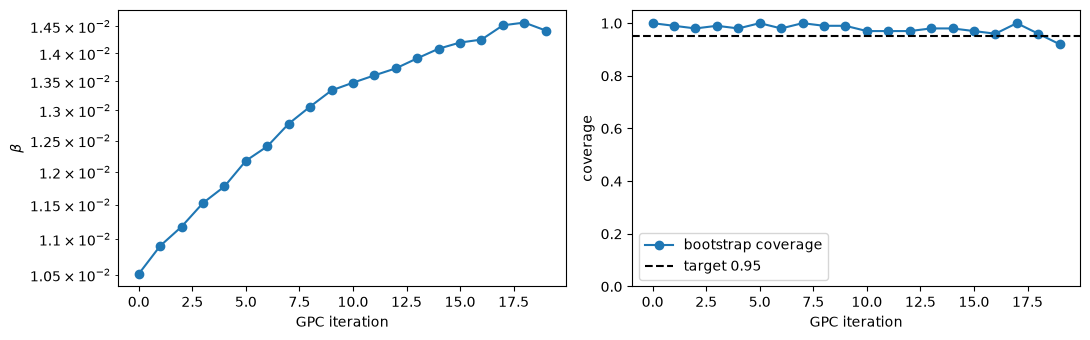

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))
ax1.plot(gpc_history["betas"], "o-")
ax1.set_yscale("log")
ax1.set_xlabel("GPC iteration")
ax1.set_ylabel(r"$\beta$")
ax2.plot(gpc_history["coverages"], "o-", label="bootstrap coverage")
ax2.axhline(0.95, color="k", ls="--", label="target 0.95")
ax2.set_xlabel("GPC iteration")
ax2.set_ylabel("coverage")
ax2.set_ylim(0, 1.05)
ax2.legend()
plt.tight_layout()
plt.show()

## 6. Calibrated posterior

With the calibrated $\beta$ the conjugate posterior is Gaussian in
closed form.

          $\log \beta$:  -0.306 ± 0.112   (true  -0.511)
         $\log \gamma$:  -1.262 ± 0.416   (true  -1.897)
$\mathrm{logit}\,\rho$:   0.640 ± 0.119   (true   0.405)
            $\log I_0$:   2.654 ± 0.232   (true   2.996)


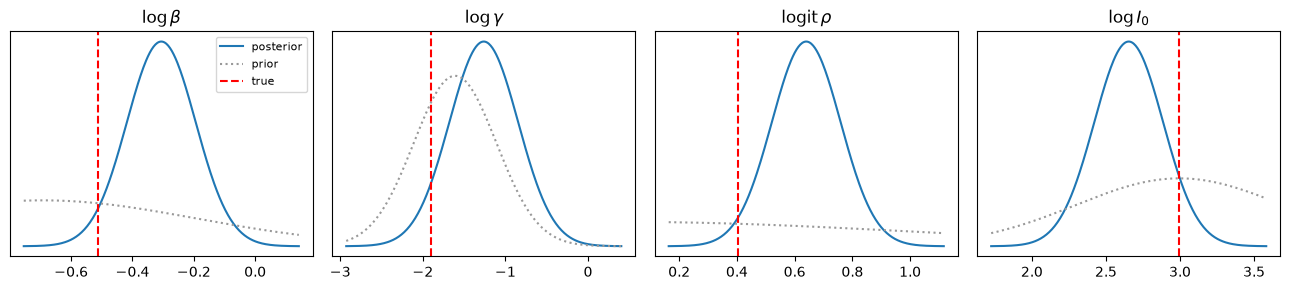

In [ ]:
mu_n, Sigma_n = posterior.calibrated_posterior(x_obs_mis, beta)
mu_n = mu_n.detach()
std_n = Sigma_n.detach().diagonal().sqrt()

labels = [r"$\log \beta$", r"$\log \gamma$", r"$\mathrm{logit}\,\rho$", r"$\log I_0$"]
for lab, m, s, t in zip(labels, mu_n, std_n, theta_true):
    print(f"{lab:>22}: {m:7.3f} ± {s:.3f}   (true {t:7.3f})")

fig, axes = plt.subplots(1, d_theta, figsize=(13, 3))
for i, ax in enumerate(axes):
    grid = torch.linspace(min(mu_n[i] - 4 * std_n[i], theta_true[i]),
                          max(mu_n[i] + 4 * std_n[i], theta_true[i]), 300)
    pdf = torch.distributions.Normal(mu_n[i], std_n[i]).log_prob(grid).exp()
    prior_pdf = torch.distributions.Normal(prior.loc[i], prior.covariance_matrix[i, i].sqrt()).log_prob(grid).exp()
    ax.plot(grid, pdf, label="posterior")
    ax.plot(grid, prior_pdf, color="0.6", ls=":", label="prior")
    ax.axvline(theta_true[i], color="r", ls="--", label="true")
    ax.set_title(labels[i])
    ax.set_yticks([])
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()